In [2]:
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

print("All libraries imported successfully!")


TensorFlow: 2.21.0
NumPy: 2.4.6
Pandas: 3.1.1
All libraries imported successfully!


In [3]:
import os
import json

from PIL import Image

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [4]:
import tensorflow as tf
import tensorflow_datasets as tfds
import importlib_resources

print("TensorFlow:", tf.__version__)
print("TFDS:", tfds.__version__)
print("All imports successful!")

TensorFlow: 2.21.0
TFDS: 4.9.10
All imports successful!


In [5]:
dataset, info = tfds.load(
    "plant_village",
    split="train",
    as_supervised=True,
    with_info=True
)

print("Dataset loaded successfully!")
print(info)

/opt/anaconda3/envs/tomato_ai/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dl Completed...: 0 url [00:00, ? url/s]
Dl Size...: 0 MiB [00:00, ? MiB/s]

Dl Completed...:   0%|                   | 0/1 [00:00<?, ? url/s]
Dl Size...: 0 MiB [00:00, ? MiB/s]

Dl Completed...: 100%|██████████| 1/1 [00:00<00:00, 311.61 url/s]
Dl Size...: 0 MiB [00:00, ? MiB/s]

Dl Size...:   0%|                | 0/868032562 [00:00<?, ? MiB/s]

Dl Completed...: 100%|██████████| 1/1 [00:00<00:00, 196.00 url/s]
Dl Size...: 100%|█| 868032562/868032562 [00:00<00:00, 18351693366

Extraction completed...: 0 file [00:00, ? file/s]
Dl Size...: 100%|█| 868032562/868032562 [00:00<00:00, 92549186479
Generating splits...:   0%|           | 0/1 [00:00<?, ? splits/s]
Generating train examples...: 0 examples [00:00, ? examples/s]
Generating train examples...: 4399 examples [00:01, 4398.80 examp
Generating train examples...: 8960 examples [00:02, 4493.71 examp
Generating train examples...: 13454 examples [00:03, 4447.35 exam
Generating train examples...: 17902 examples [00:04, 4027.40 exam
Generating 

Dataset plant_village downloaded and prepared to /Users/soumyaranjanmeher/tensorflow_datasets/plant_village/1.0.2. Subsequent calls will reuse this data.
Dataset loaded successfully!
tfds.core.DatasetInfo(
    name='plant_village',
    full_name='plant_village/1.0.2',
    description="""
    The PlantVillage dataset consists of 54303 healthy and unhealthy leaf images
    divided into 38 categories by species and disease.
    
    NOTE: The original dataset is not available from the original source
    (plantvillage.org), therefore we get the unaugmented dataset from a paper that
    used that dataset and republished it. Moreover, we dropped images with
    Background_without_leaves label, because these were not present in the original
    dataset.
    
    Original paper URL: https://arxiv.org/abs/1511.08060 Dataset URL:
    https://data.mendeley.com/datasets/tywbtsjrjv/1
    """,
    homepage='https://arxiv.org/abs/1511.08060',
    data_dir='/Users/soumyaranjanmeher/tensorflow_dataset

In [6]:
import re

label_names = info.features["label"].names

tomato_count = 0

for image, label in tfds.as_numpy(dataset):

    class_name = label_names[int(label)]

    if class_name.startswith("Tomato___"):

        disease_name = class_name.replace("Tomato___", "")
        disease_name = re.sub(r'[<>:"/\\|?*]', "_", disease_name)

        save_folder = os.path.join(
            "data/tomato",
            disease_name
        )

        os.makedirs(save_folder, exist_ok=True)

        image_path = os.path.join(
            save_folder,
            f"tomato_{tomato_count}.jpg"
        )

        Image.fromarray(image).save(image_path)

        tomato_count += 1

print("Tomato images extracted:", tomato_count)

I0000 00:00:1795060298.726140 13435169 tf_record_dataset_op.cc:396] The default buffer size is 262144, which is overridden by the user specified `buffer_size` of 8388608


Tomato images extracted: 18159


In [7]:
for folder in os.listdir("data/tomato"):

    path = os.path.join("data/tomato", folder)

    if os.path.isdir(path):
        print(folder, ":", len(os.listdir(path)), "images")

Late_blight : 1908 images
Septoria_leaf_spot : 1771 images
Tomato_Yellow_Leaf_Curl_Virus : 5357 images
healthy : 1591 images
Early_blight : 1000 images
Target_Spot : 1404 images
Leaf_Mold : 952 images
Tomato_mosaic_virus : 373 images
Bacterial_spot : 2127 images
Spider_mites Two-spotted_spider_mite : 1676 images


In [8]:
import splitfolders

splitfolders.ratio(
    "data/tomato",
    output="data/split",
    seed=42,
    ratio=(0.70, 0.15, 0.15)
)

print("Dataset split completed!")

Copying files: 18159 files [00:05, 3253.24 files/s]

Dataset split completed!


In [9]:
#image preprocessing
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    "data/split/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    "data/split/val",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    "data/split/test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_ds.class_names

print("Disease classes:", class_names)
print("Total classes:", len(class_names))

Found 12706 files belonging to 10 classes.
Found 2719 files belonging to 10 classes.
Found 2734 files belonging to 10 classes.
Disease classes: ['Bacterial_spot', 'Early_blight', 'Late_blight', 'Leaf_Mold', 'Septoria_leaf_spot', 'Spider_mites Two-spotted_spider_mite', 'Target_Spot', 'Tomato_Yellow_Leaf_Curl_Virus', 'Tomato_mosaic_virus', 'healthy']
Total classes: 10


In [10]:
#normalize image
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

val_ds = val_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

test_ds = test_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Preprocessing completed!")

Preprocessing completed!


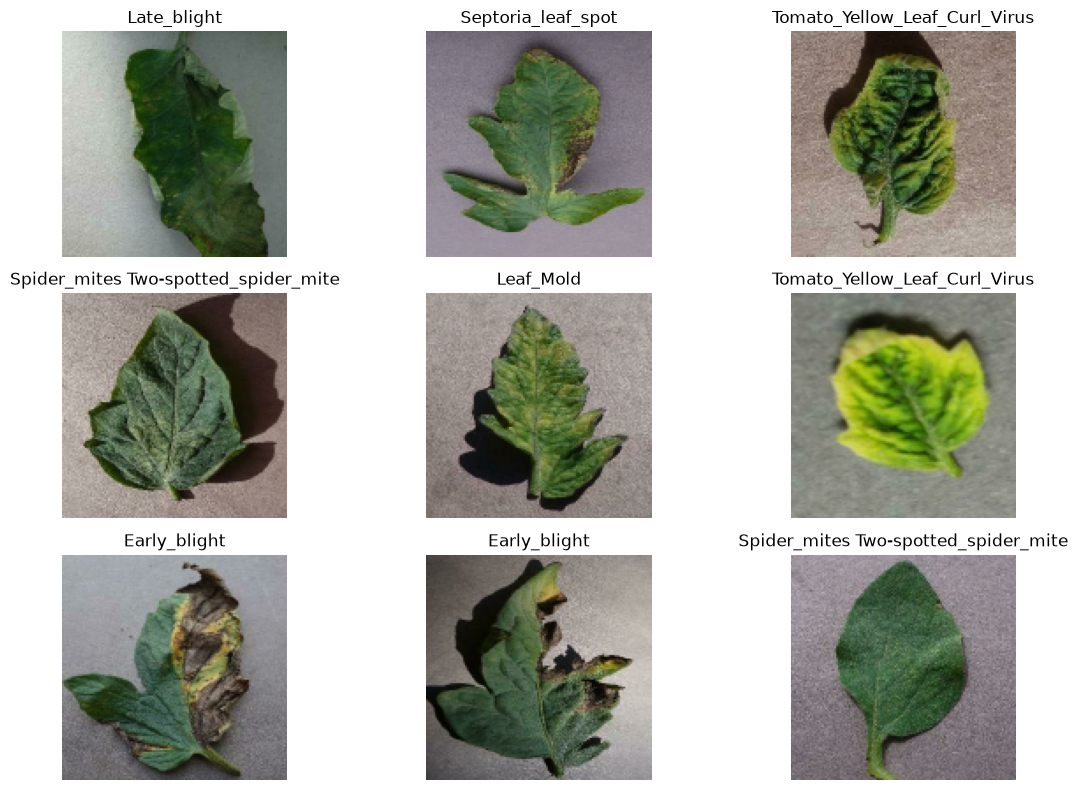

In [11]:
#visualize image
plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):

    for i in range(9):

        plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy())

        plt.title(class_names[int(labels[i])])

        plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
#create cnn
from tensorflow.keras import layers, models

model = models.Sequential([

    layers.Input(shape=(128, 128, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),

    layers.Dropout(0.5),

    layers.Dense(len(class_names), activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,930 (12.61 MB)

 Trainable params: 3,305,930 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
#model compilation
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [14]:
#train the model
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stop]
)

Epoch 1/15


/opt/anaconda3/envs/tomato_ai/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


398/398 ━━━━━━━━━━━━━━━━━━━━ 70s 173ms/step - accuracy: 0.6007 - loss: 1.1899 - val_accuracy: 0.8246 - val_loss: 0.5904
Epoch 2/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 66s 166ms/step - accuracy: 0.7759 - loss: 0.6721 - val_accuracy: 0.8003 - val_loss: 0.5424
Epoch 3/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 65s 164ms/step - accuracy: 0.8321 - loss: 0.4953 - val_accuracy: 0.8878 - val_loss: 0.3222
Epoch 4/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 66s 166ms/step - accuracy: 0.8598 - loss: 0.4022 - val_accuracy: 0.9088 - val_loss: 0.2822
Epoch 5/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 67s 168ms/step - accuracy: 0.8881 - loss: 0.3443 - val_accuracy: 0.8841 - val_loss: 0.3322
Epoch 6/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 65s 164ms/step - accuracy: 0.9063 - loss: 0.2774 - val_accuracy: 0.8926 - val_loss: 0.3047
Epoch 7/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 67s 169ms/step - accuracy: 0.9157 - loss: 0.2537 - val_accuracy: 0.9139 - val_loss: 0.2552
Epoch 8/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 439s 1s/step - accuracy: 0.9250 - loss: 0.2178 - val_a

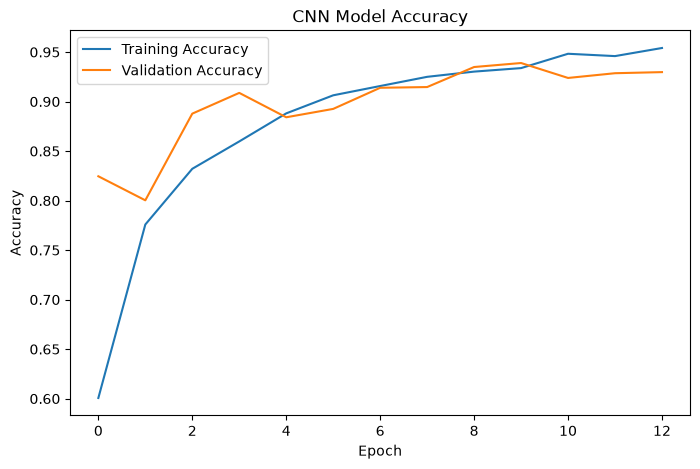

In [15]:
#plot accuracy
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")

plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Model Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.show()

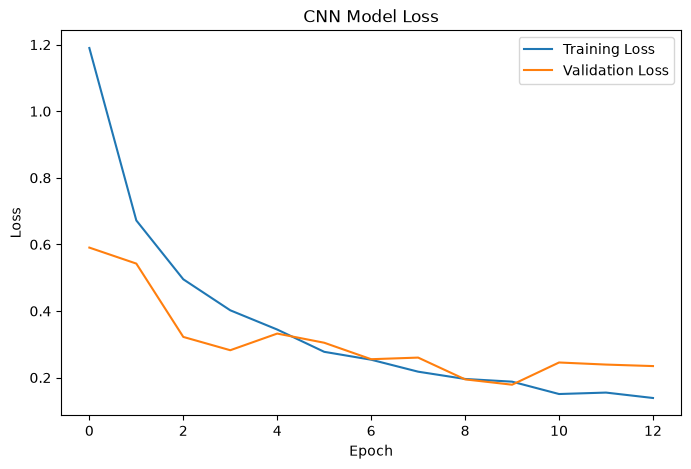

In [16]:
#plot loss
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")

plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("CNN Model Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.show()

In [17]:
#evaluate the model,
#test accuracy
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)

print("Test Accuracy:", test_accuracy * 100, "%")

86/86 ━━━━━━━━━━━━━━━━━━━━ 4s 47ms/step - accuracy: 0.9514 - loss: 0.1499
Test Loss: 0.14985114336013794
Test Accuracy: 95.13533115386963 %


In [18]:
#confusion matrix and classification report
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

y_true = []
y_pred = []

for images, labels in test_ds:

    predictions = model.predict(images, verbose=0)

    predicted_classes = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())

    y_pred.extend(predicted_classes)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

                                      precision    recall  f1-score   support

                      Bacterial_spot       0.96      0.98      0.97       320
                        Early_blight       0.88      0.83      0.85       150
                         Late_blight       0.94      0.92      0.93       287
                           Leaf_Mold       0.96      0.83      0.89       144
                  Septoria_leaf_spot       0.91      0.94      0.92       267
Spider_mites Two-spotted_spider_mite       0.91      0.98      0.94       252
                         Target_Spot       0.92      0.92      0.92       212
       Tomato_Yellow_Leaf_Curl_Virus       0.99      0.99      0.99       805
                 Tomato_mosaic_virus       0.95      0.93      0.94        57
                             healthy       1.00      0.99      0.99       240

                            accuracy                           0.95      2734
                           macro avg       0.94      0.93     

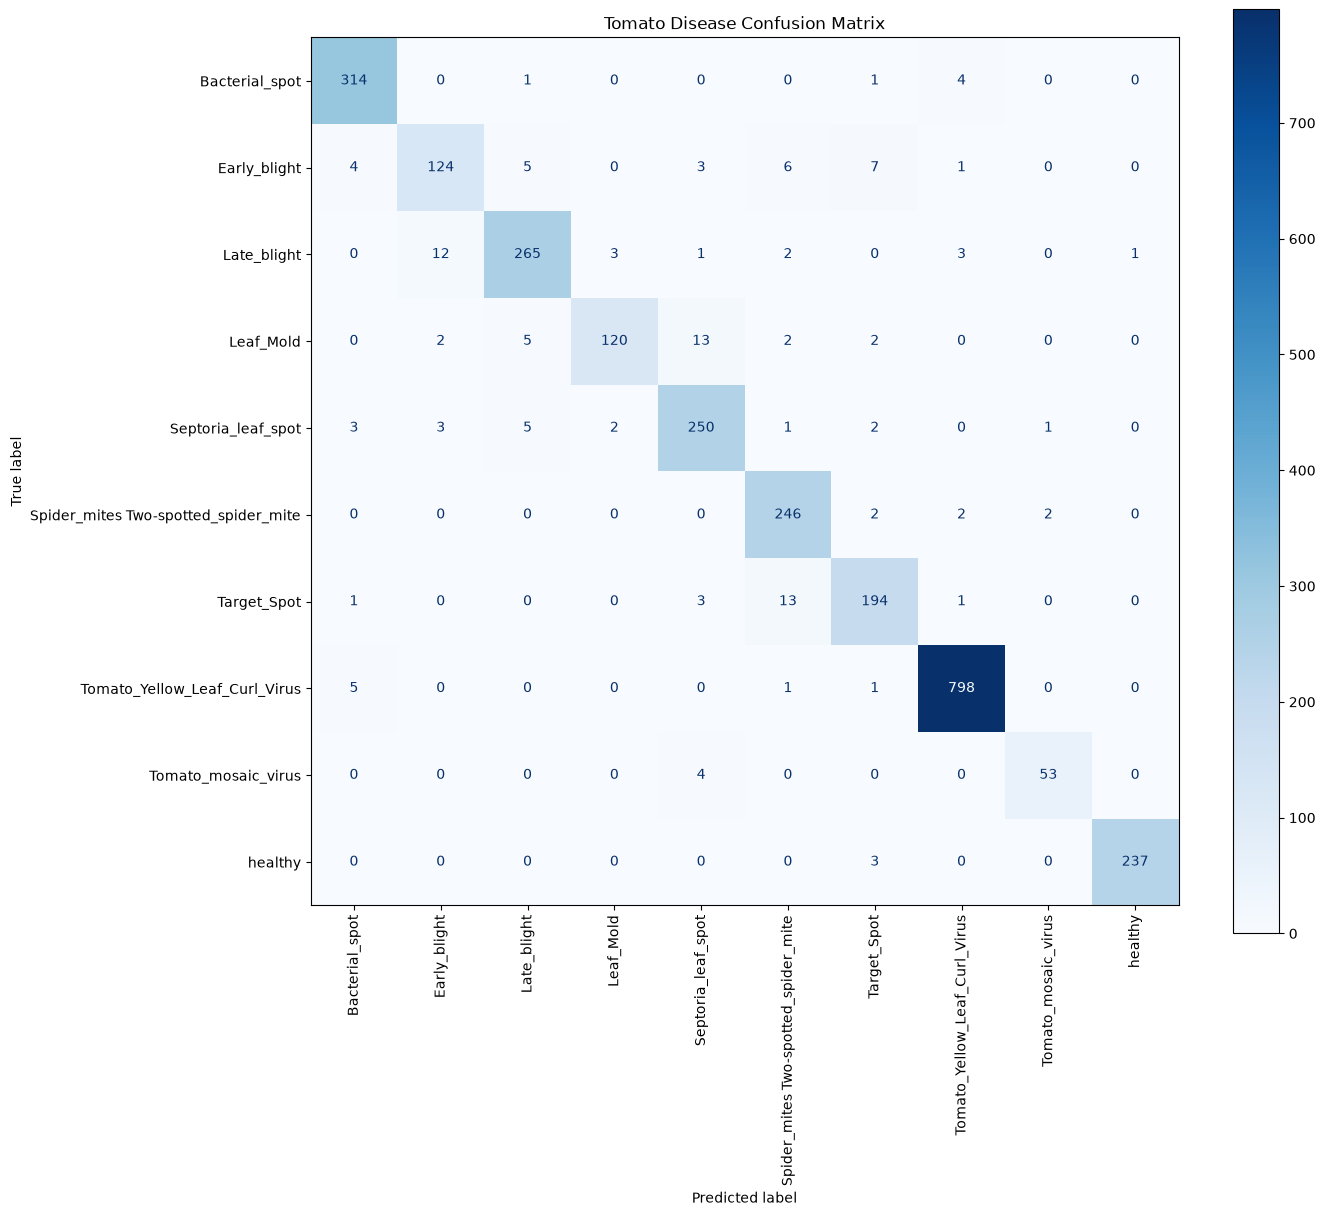

In [19]:
#visualization of confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(14, 12))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    xticks_rotation=90,
    cmap="Blues",
    ax=plt.gca()
)

plt.title("Tomato Disease Confusion Matrix")

plt.show()

In [20]:
#Save the trained model
os.makedirs("models", exist_ok=True)

model.save("models/tomato_disease_model.keras")

with open("class_names.json", "w") as file:
    json.dump(class_names, file)

print("Model saved successfully!")

Model saved successfully!


In [21]:
#Your project now has:
#models/tomato_disease_model.keras
#class_names.json

In [24]:
import os
print(os.path.exists("test_leaf.jpg"))

False


In [25]:
print(os.getcwd())

/Users/soumyaranjanmeher


In [26]:
import os

os.chdir("/Users/soumyaranjanmeher/Documents/tomato_disease_prediction")

print(os.getcwd())

/Users/soumyaranjanmeher/Documents/tomato_disease_prediction


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 190ms/step


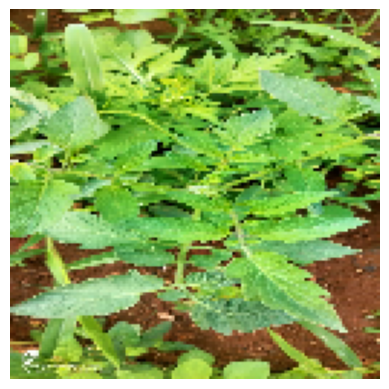

Predicted Disease: Tomato_Yellow_Leaf_Curl_Virus
Confidence: 100.0 %


In [28]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

img_path = "test_leaf.jpg"

img = image.load_img(img_path, target_size=(128, 128))

img_array = image.img_to_array(img)
img_array = img_array / 255.0
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array)

predicted_index = np.argmax(prediction[0])
predicted_disease = class_names[predicted_index]

confidence = prediction[0][predicted_index] * 100

plt.imshow(img)
plt.axis("off")
plt.show()

print("Predicted Disease:", predicted_disease)
print("Confidence:", round(float(confidence), 2), "%")